<a href="https://colab.research.google.com/github/purinpurin11/Micas-blancas/blob/P-Caddick-%26-Thompson-(2008)-para-Si-en-fengita-(1)/Caddick_%26_Thompson_(2008)_para_Si_en_fengita_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
# ============================================================
# Cálculo de presiones con barómetro Mg-Si en fengita
# Fórmula:
# P(GPa) = 8.35*Mg - 1.72*Si + 0.0015*T(K) + 4.59
# ============================================================

!pip install openpyxl -q

import pandas as pd
from google.colab import files

# 1. Subir archivo
print("Sube el archivo APFU_mica_blanca_11O.csv o .xlsx")
uploaded = files.upload()

archivo = list(uploaded.keys())[0]
print("Archivo cargado:", archivo)

# 2. Leer archivo
if archivo.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(archivo)
else:
    df = pd.read_csv(archivo)

# Limpiar nombres de columnas
df.columns = df.columns.str.strip()

# 3. Verificar columnas necesarias
for col in ["Si", "Mg"]:
    if col not in df.columns:
        raise ValueError(f"No se encontró la columna '{col}' en el archivo.")

# Verificar o crear columna Muestra
if "Muestra" not in df.columns:
    df = df.rename(columns={df.columns[0]: "Muestra"})

# 4. Temperaturas solicitadas
temperaturas = [
    ("468C", 468.0),
    ("519.75C", 519.75),
    ("571.5C", 571.5),
    ("623.25C", 623.25),
    ("675C", 675.0)
]

# 5. Calcular presiones con la nueva fórmula
for nombre, T_C in temperaturas:
    T_K = T_C + 273.15
    df[f"P_GPa_{nombre}"] = (
        8.35 * df["Mg"]
        - 1.72 * df["Si"]
        + 0.0015 * T_K
        + 4.59
    )

# 6. Seleccionar columnas de salida
columnas_salida = [
    "Muestra",
    "P_GPa_468C",
    "P_GPa_519.75C",
    "P_GPa_571.5C",
    "P_GPa_623.25C",
    "P_GPa_675C"
]

resultado = df[columnas_salida].copy()

# 7. Exportar a Excel con una sola hoja
nombre_salida = "Presiones_muestras.xlsx"

with pd.ExcelWriter(nombre_salida, engine="openpyxl") as writer:
    resultado.to_excel(
        writer,
        sheet_name="Presiones_muestras",
        index=False
    )

# 8. Mostrar resultado y descargar
display(resultado)

files.download(nombre_salida)

Sube el archivo APFU_mica_blanca_11O.csv o .xlsx


Saving APFU_mica_blanca_11O.csv to APFU_mica_blanca_11O (5).csv
Archivo cargado: APFU_mica_blanca_11O (5).csv


,Muestra,P_GPa_468C,P_GPa_519.75C,P_GPa_571.5C,P_GPa_623.25C,P_GPa_675C
0,A2,3.392993,3.470618,3.548243,3.625868,3.703493
1,A3,3.660729,3.738354,3.815979,3.893604,3.971229
2,A4,3.034105,3.111730,3.189355,3.266980,3.344605
3,A5,2.513816,2.591441,2.669066,2.746691,2.824316
4,A6,4.423755,4.501380,4.579005,4.656630,4.734255
5,A7,4.369435,4.447060,4.524685,4.602310,4.679935
6,A8,4.722203,4.799828,4.877453,4.955078,5.032703
7,A9,3.951491,4.029116,4.106741,4.184366,4.261991
8,A10,4.928480,5.006105,5.083730,5.161355,5.238980
9,A11,4.281901,4.359526,4.437151,4.514776,4.592401


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Sube el archivo Presiones_muestras.xlsx


Saving Presiones_muestras (1).xlsx to Presiones_muestras (1) (2).xlsx
Archivo cargado: Presiones_muestras (1) (2).xlsx
Temperaturas detectadas: [468.0, 519.75, 571.5, 623.25, 675.0]
Columnas de presión: ['P_GPa_468C', 'P_GPa_519.75C', 'P_GPa_571.5C', 'P_GPa_623.25C', 'P_GPa_675C']


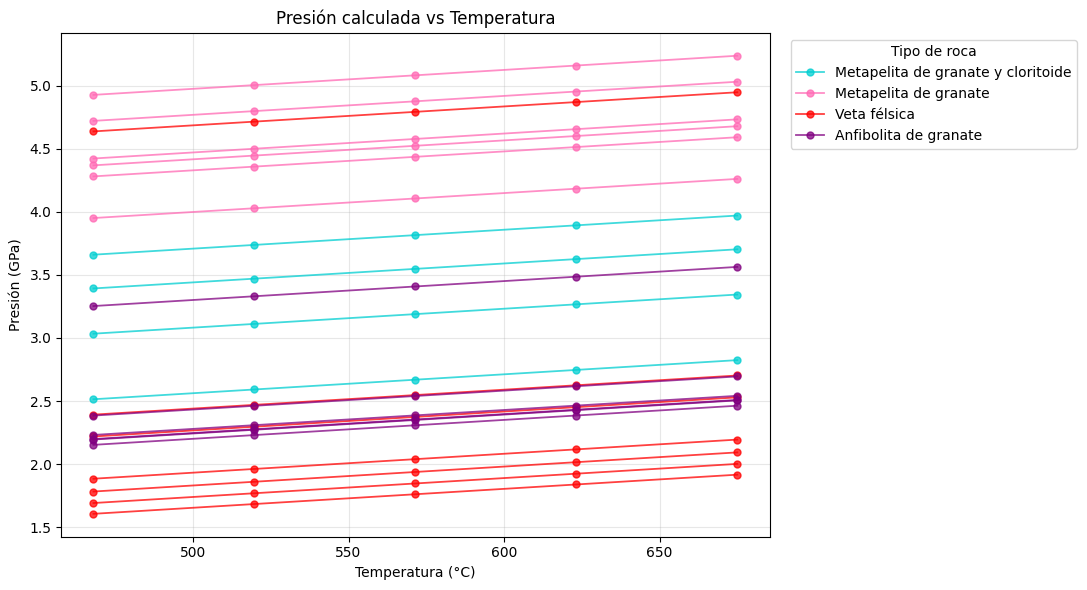

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ============================================================
# Gráfico Temperatura vs Presión
# Colores por tipo de roca
# ============================================================

!pip install openpyxl -q

import pandas as pd
import matplotlib.pyplot as plt
import re
from google.colab import files

# 1. Subir archivo Excel
print("Sube el archivo Presiones_muestras.xlsx")
uploaded = files.upload()

archivo = list(uploaded.keys())[0]
print("Archivo cargado:", archivo)

# 2. Leer hoja Presiones_muestras
df = pd.read_excel(archivo, sheet_name="Presiones_muestras")

# 3. Detectar columnas de presión: P_GPa_468C, P_GPa_571.5C, etc.
columnas_presion = [
    c for c in df.columns
    if str(c).startswith("P_GPa_")
]

def extraer_temperatura(columna):
    """
    Extrae la temperatura desde el nombre de columna.
    Ejemplo: P_GPa_571.5C -> 571.5
    """
    match = re.search(r"P_GPa_([0-9.]+)C", str(columna))
    return float(match.group(1))

# Ordenar columnas por temperatura
pares_temp_col = sorted(
    [(extraer_temperatura(c), c) for c in columnas_presion],
    key=lambda x: x[0]
)

temperaturas = [p[0] for p in pares_temp_col]
columnas_P = [p[1] for p in pares_temp_col]

print("Temperaturas detectadas:", temperaturas)
print("Columnas de presión:", columnas_P)

# 4. Colores solicitados por tipo de roca
colores = {
    "Metapelita de granate y cloritoide": "#00CED1",  # azul cian
    "Metapelita de granate": "#FF69B4",               # rosa
    "Veta félsica": "#FF0000",                        # rojo
    "Anfibolita de granate": "#800080"                # morado
}

# 5. Crear gráfico
plt.figure(figsize=(11, 6))

vistos = set()

for _, fila in df.iterrows():
    roca = fila["Tipo de roca"]
    color = colores.get(roca, "gray")
    y = fila[columnas_P].astype(float).values

    # Para que la leyenda no repita el mismo tipo de roca
    etiqueta = roca if roca not in vistos else None

    plt.plot(
        temperaturas,
        y,
        marker="o",
        color=color,
        alpha=0.75,
        linewidth=1.3,
        markersize=5,
        label=etiqueta
    )

    vistos.add(roca)

plt.xlabel("Temperatura (°C)")
plt.ylabel("Presión (GPa)")
plt.title("Presión calculada vs Temperatura")
plt.grid(True, alpha=0.3)

# Se posiciona la leyenda afuera en la esquina superior derecha para que no estorbe
plt.legend(title="Tipo de roca", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()

# 6. Guardar y descargar gráfico
nombre_png = "Grafico_Presiones_vs_Temperatura.png"
plt.savefig(nombre_png, dpi=300, bbox_inches="tight")
plt.show()

files.download(nombre_png)